## Spatial Transcriptomics Tutorial
This tutorial demonstrates how to run SpaceBender in a Python Jupyter notebook.

It includes the following sections:

0. Code for the generation of the toy dataset used in this notebook.
1. Running SpaceBender on the raw AnnData object (H5AD file) with details on parameter choice.
2. Explanation of model outputs and basic downstream analysis with Scanpy.

### Install Packages
Users using MacBooks may benefit from running the first three lines of the block. The SpaceBender package is provided on GitHub and can be installed via `git clone`. Users can then add the package to their path (and thus accessible by the notebook) through the `sys` package (code below). For example, if the package was installed in "/path/to/package/SpaceBender/spacebender.py" then the `sys.path.insert` code would be pointing to "/path/to/package".

Users may also choose to run SpaceBender on Google Colab (e.g. to use their free online GPU); they will need to install pre-requisite packages (e.g. pytorch and pyro) prior to running SpaceBender. If users have access to a GPU (remotely or locally), we recommend this to significantly speed up SpaceBender model training and denoising (batch size can be lowered to accommodate lower memory GPUs).

In [1]:
# enable fallback for MPS (MacBook) use cases
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

# import packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import sys
import warnings
# adjust figure aesthetics
sc.set_figure_params(dpi=100)
warnings.filterwarnings('ignore')
# add package to PATH (this is where you installed the GitHub package)
sys.path.insert(0, "/PATH/TO/SPACEBENDER")
from SpaceBender import spacebender

### Part 0: Simulating a Toy Dataset
The following code provides details for how the toy dataset provided in this repository was derived. This information is NOT necessary to run SpaceBender but is simply provided for full transparency.

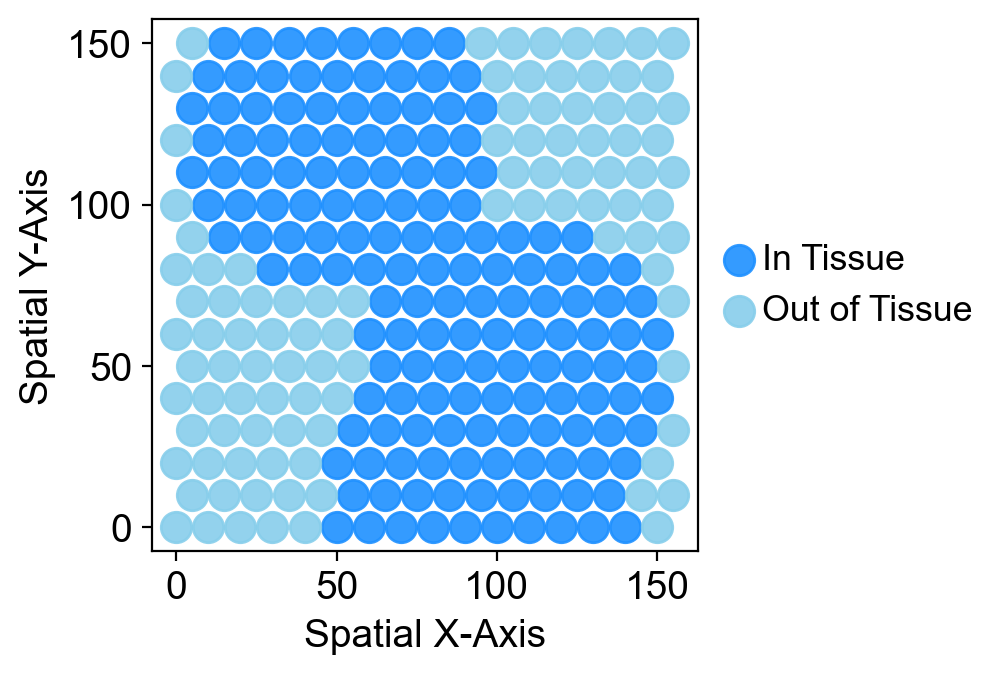

In [2]:
from scipy.spatial.distance import cdist
# define parameters for spot-grid generation
spot_dist = 10  # distance between spots
xmin, xmax = 0, 150
ymin, ymax = 0, 150
# generate a set of spots in off-set rows (e.g. like Visium)
coords = list(np.meshgrid(np.arange(xmin, xmax+1, spot_dist),
                          np.arange(ymin, ymax+1, spot_dist)))
coords[0] = [row + spot_dist / 2 if i % 2 == 0 else row for i, row in enumerate(coords[0])]
coords = pd.DataFrame(np.array(coords).T.reshape(-1, 2), columns=['x_location','y_location'])

# define which spots are in tissue
# > simulate by randomly choosing ten spots and their neighbors as "in tissue"
np.random.seed(0)
idxs = np.random.choice(coords.index, size=3, replace=False)
distances = pd.DataFrame(cdist(coords.loc[idxs], coords), index=idxs, columns=coords.index)
in_tissue = (distances < 50).any(axis=0)
# > visualize the tissue
fig, ax = plt.subplots(figsize=[3.5, 3.5]); _ = ax.grid(False)  # "150-" is to keep orientation with later plots
_ = ax.scatter(coords.loc[in_tissue, 'x_location'], 150-coords.loc[in_tissue, 'y_location'],
               marker='o', s=120, color='dodgerblue', alpha=0.9, label='In Tissue')
_ = ax.scatter(coords.loc[~in_tissue, 'x_location'], 150-coords.loc[~in_tissue, 'y_location'],
               marker='o', s=120, color='skyblue', alpha=0.9, label='Out of Tissue')
_ = ax.legend(bbox_to_anchor=(1, .5), bbox_transform=ax.transAxes, frameon=False, loc='center left')
_ = ax.set(xlabel='Spatial X-Axis', ylabel='Spatial Y-Axis')

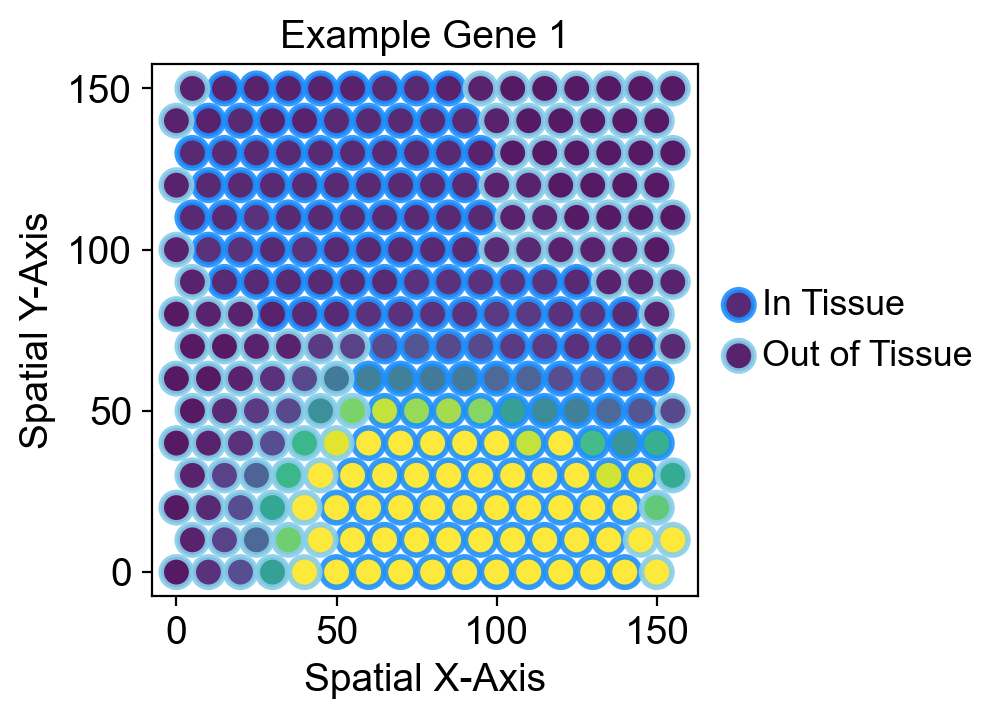

In [3]:
from scipy.cluster.hierarchy import linkage, fcluster
# simulate spatially-associated "cell type" specific expression with ten genes
# > define cell type specific expression, similar cells have similar expression
n_clusters, n_genes = 3, 9
clusters = pd.Series(fcluster(linkage(distances, method='ward'), t=n_clusters, criterion='maxclust'), index=idxs)
np.random.seed(0)
cluster2weights = {}
step_size = round(n_genes / n_clusters)  # number of genes / cluster
for i in range(n_clusters):
    # randomly sample background
    v = np.random.uniform(0, 5, size=n_genes).round()
    # set high counts for the cluster's fraction of the genome
    start, end = i * step_size, (i+1) * step_size
    end = n_genes if i == n_clusters else end
    v[start:end] = 200
    cluster2weights[i+1] = v
# > map each spot to an anchoring index
spot2idx = distances.idxmin(axis=0)
# > generate counts for in tissue spots next to each cluster
counts = pd.DataFrame(0, index=coords.index, columns=np.arange(n_genes))
for cluster in clusters.unique():
    # identify the anchoring indices for this clusters
    cluster_idxs = clusters.index[clusters == cluster]
    # sample counts for in tissue cells in this cluster
    spots = spot2idx.index[spot2idx.isin(cluster_idxs) & in_tissue]
    # retrieve the weights for the poisson distribution for this cluster
    weights = cluster2weights[cluster]
    counts.loc[spots] = np.random.poisson(lam=weights, size=(spots.shape[0], n_genes))

# simulate diffusion from each spot
distances = pd.DataFrame(cdist(coords, coords), index=coords.index, columns=coords.index)
weights = (1 / ((distances / 100) + 1)) ** 12  # favor nearby spots via decay
weights[weights < 1e-2] = 0  # filter out spots that are too far to be impacted
dropouts = np.random.uniform(size=weights.shape) >= 0.9 # add random drop outs (10%)
weights[dropouts] = 0
weights = (weights.T / weights.sum(axis=1)).T  # normalize so that row sums (spatial weights) equal one
counts = (weights @ counts).round().astype(int)

# plot an example gene
fig, ax = plt.subplots(figsize=[3.5, 3.5]); _ = ax.grid(False)
_ = ax.scatter(coords.loc[in_tissue, 'x_location'], 150-coords.loc[in_tissue, 'y_location'],
               marker='o', s=120, edgecolor='dodgerblue', alpha=0.9, label='In Tissue',
               c=counts.loc[in_tissue, 0], cmap='viridis', vmin=0, vmax=40, linewidth=2)
_ = ax.scatter(coords.loc[~in_tissue, 'x_location'], 150-coords.loc[~in_tissue, 'y_location'],
               marker='o', s=120, edgecolor='skyblue', alpha=0.9, label='Out of Tissue',
               c=counts.loc[~in_tissue, 0], cmap='viridis', vmin=0, vmax=40, linewidth=2)
_ = ax.legend(bbox_to_anchor=(1, .5), bbox_transform=ax.transAxes, frameon=False, loc='center left')
_ = ax.set(xlabel='Spatial X-Axis', ylabel='Spatial Y-Axis', title='Example Gene 1')

In [4]:
import anndata
from scipy.sparse import csr_matrix
# assemble the anndata object using the diffused counts
adata = anndata.AnnData(csr_matrix(counts))
# rename the genes and observations
adata.obs.index = 'Spot' + (adata.obs.index.astype(int) + 1).astype(str)
adata.var.index = 'Gene' + (adata.var.index.astype(int) + 1).astype(str)
# add on the annotation of which spots are in tissue
adata.obs['in_tissue'] = (in_tissue * 1).values
# add on the spatial coordinations
adata.obsm['spatial'] = coords.astype(float).values
# save the object as toy data
input_file = 'ToyData.h5ad'
adata.write_h5ad(input_file)

### Part 1: Running SpaceBender
SpaceBender reads an [Anndata](https://anndata.readthedocs.io) object saved as an H5AD file.

The file needs to include the following attributes:

- `.X`: storing the **raw** (i.e. integer) counts (in the standard observations by genes format)
- `.obs['in_tissue']`: an observation-level annotation of which spots/cells contain tissue (1) versus are empty (0); empty spots are important for denoising but are not strictly necessary (they can be defined for single-cell-/subcellular-resolution spatial data by using a lenient # of reads cutoff)
- `.obsm['spatial']`: the x- and y-coordinates of each observation (this can be defined in any units noting that the units used for the spatial coordinates are the same as used for the model's `ambient_radius` parameter)

Below, we implement the `run_spacebender` function which 1) reads the input H5AD, 2) trains the SpaceBender model, 3) samples the denoised counts, and 4) writes the denoised counts to a new H5AD file.

The key model parameters are as follows:

| Parameter | Description | Typical Values |
|---|---|---|
| `k_neighbors` | # of nearest observations used for the local ambient profile (`None` to use `ambient_radius`) | e.g. 6, 18, or 36 for Visium 55µm-resolution |
| `ambient_radius` | radius in the `.obsm['spatial']` units to define neighborhoods for ambient RNA profiles (used if `k_neighbors=None`) | this depends on the degree of diffusion you expect for your data, users may benefit from first analyzing the spatial distribution of their data and increasing or decreasing this parameter to account for greater or lesser diffusion, respectively |
| `n_epochs` | # of training epochs | 50-200 (this depends on the learning rate, increase the # of epochs and decrease learning rate if you notice the model exhibiting unstable loss values between iterations) |
| `batch_size` | # of observations to use per batch | 128-512 (this depends on the CPU or GPU memory you have access to) |
| `device` | `'cpu'`, `'cuda'` | we recommend using a GPU if you have access to one (`'cuda'`) to speed up model running |

The other parameters are fairly default and do not typically require any tuning.

In [5]:
# define input and output files
input_file = 'ToyData.h5ad'
output_file = input_file.replace('.h5ad','.OUT.h5ad')
# run spacebender model
spacebender.run_spacebender(
    input_file=input_file,
    output_file=output_file,
    k_neighbors=None,
    ambient_radius=300,
    n_epochs=100,
    batch_size=256,
    learning_rate=2e-4,
    z_dim=64,
    n_posterior_samples=25,
    device='cpu',
    train_in_tissue_only=False,
    random_seed=0)
print(output_file)

2026-11-24 00:04:07,483 INFO spatial_cellbender: Loading data from ToyData.h5ad
2026-11-24 00:04:07,491 INFO spatial_cellbender: Retaining 9 / 9 genes after filtering.
2026-11-24 00:04:07,493 INFO spatial_cellbender: Computing spatial ambient RNA profiles (radius=300)...
2026-11-24 00:04:07,502 INFO spatial_cellbender: SpatialTxDataset instantiated with 256 spots and 9 genes: 156 observations in-tissue and 100 observations out-of-tissue
2026-11-24 00:04:07,503 INFO spatial_cellbender: Building SpatialRemoveBackgroundModel
2026-11-24 00:04:07,507 INFO spatial_cellbender: Training
2026-11-24 00:04:07,508 INFO spatial_cellbender: Training on all spots.
2026-11-24 00:04:08,449 INFO spatial_cellbender: Epoch    1/100 | ELBO: -167.48
2026-11-24 00:04:08,697 INFO spatial_cellbender: Epoch   10/100 | ELBO: -126.87
2026-11-24 00:04:08,991 INFO spatial_cellbender: Epoch   20/100 | ELBO: -113.30
2026-11-24 00:04:10,358 INFO spatial_cellbender: Epoch   30/100 | ELBO: -156.61
2026-11-24 00:04:15,09

ToyData.OUT.h5ad


### Part 2: Analyzing SpaceBender Output
Here, we provide code for a simple analysis of SpaceBender outputs.

It covers the following steps:
- A) Quantification of denoising (e.g. # of counts removed)
- B) Comparison of raw and denoised data dimension reduction
- C) Comparison of marker gene expression per cell type

Here, we report the number of counts removed from observations with ("tissue spots") and without ("empty spots") tissue. We then quantify the total number of counts per observation pre- and post-SpaceBender denoising (stored in `ad_rw` and `ad_sb` objects, respectively). We then plot the spatial distributions of these counts, as well as the change after denoising, to highlight how empty spots were depleted of noise and intra-tissue spots also received a degree of denoising (removal of contaminating counts).

In [6]:
# read in the original (raw) data and output (SpaceBender denoised)
ad_rw = sc.read_h5ad(input_file)
ad_sb = sc.read_h5ad(output_file)
# report the change in counts
mask = ad_rw.obs['in_tissue'].values == 1
print(f'empty spots: {ad_rw.X[~mask].sum():.0f} -> {ad_sb.X[~mask].sum():.0f} counts')
print(f'tissue spots: {ad_rw.X[mask].sum():.0f} -> {ad_sb.X[mask].sum():.0f} counts')

empty spots: 11475 -> 108 counts
tissue spots: 85543 -> 75140 counts


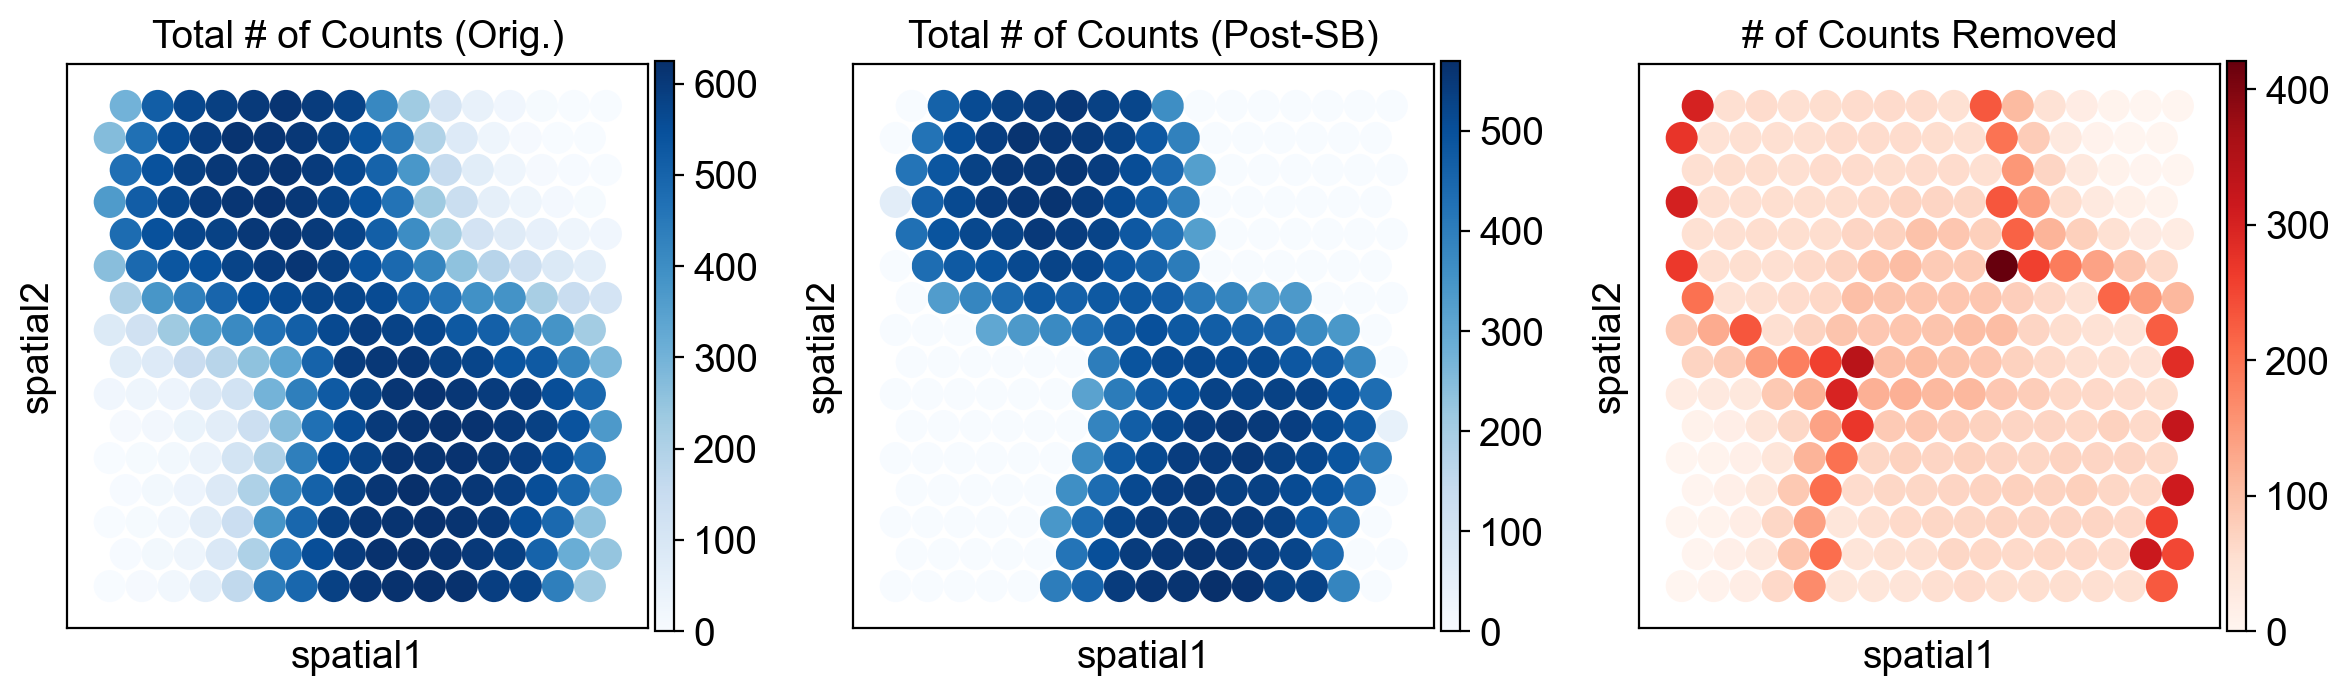

In [7]:
# quantify total number of counts per observation and the counts removed
ad_rw.obs['total_counts'] = ad_rw.X.sum(1).A1
ad_sb.obs['total_counts'] = ad_sb.X.sum(1).A1
ad_sb.obs['removed'] = ad_rw.obs['total_counts'] - ad_sb.obs['total_counts']
# plot the spatial distributions of these values
fig, axes = plt.subplots(1, 3, figsize=[12, 3.5])
sc.pl.spatial(ad_rw, color='total_counts', spot_size=10, cmap='Blues', ax=axes[0], show=False, title='Total # of Counts (Orig.)')
sc.pl.spatial(ad_sb, color='total_counts', spot_size=10, cmap='Blues', ax=axes[1], show=False, title='Total # of Counts (Post-SB)')
sc.pl.spatial(ad_sb, color='removed', spot_size=10, cmap='Reds', ax=axes[2], show=False, title='# of Counts Removed')
plt.tight_layout(); plt.show()

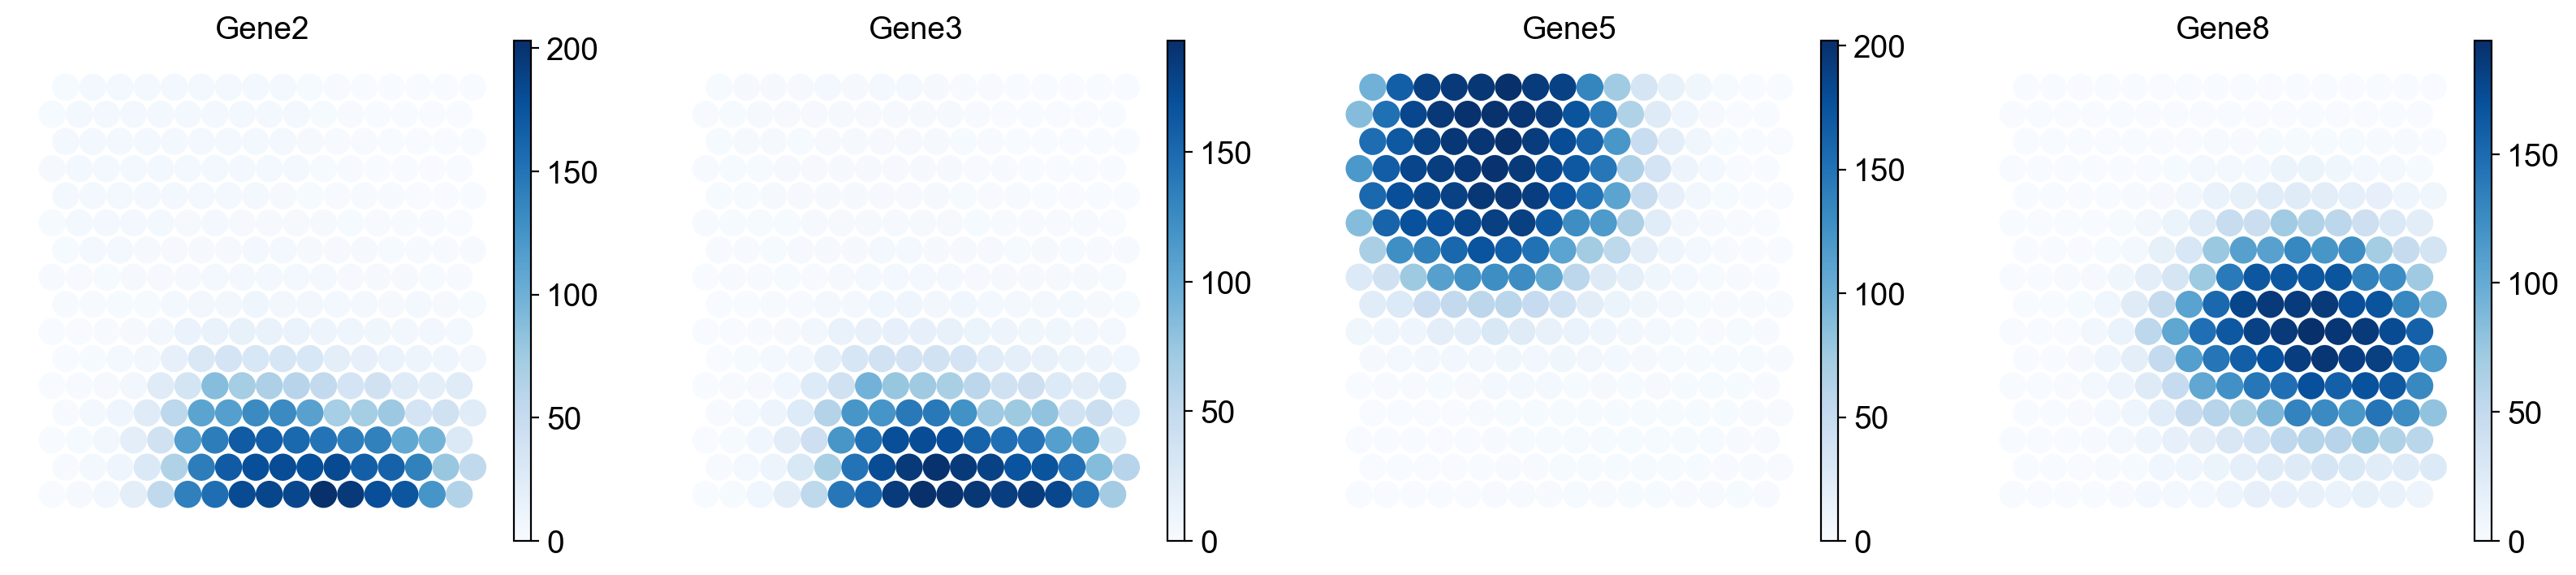

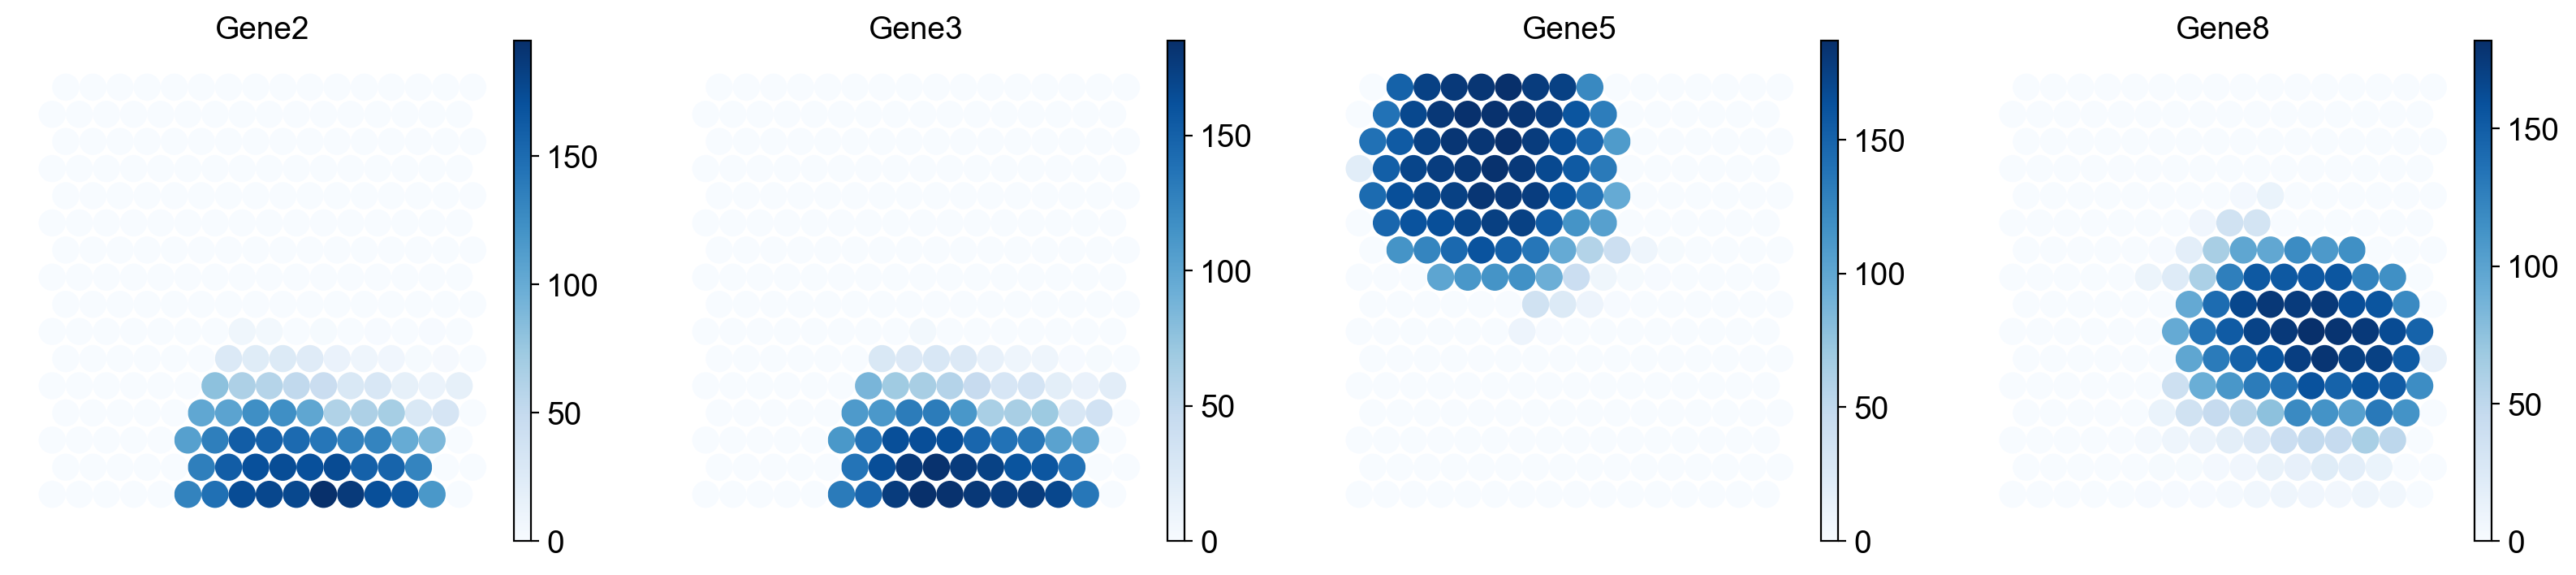

In [8]:
# view single genes before and after SpaceBender denoising (a random set of four are chosen)
np.random.seed(0)
genes = sorted(np.random.choice(ad_rw.var.index, size=4, replace=False))
sc.pl.spatial(ad_rw, color=genes, spot_size=10, cmap='Blues', frameon=False)
sc.pl.spatial(ad_sb, color=genes, spot_size=10, cmap='Blues', frameon=False)

Here, we map on our original "Cell Type" annotations to the original and denoised datasets and analyze how these cell types, and their marker genes, have changed after SpaceBender processing. We use the cell type annotation that was used to create these toy datasets; users should replace this value with their own parameter of interest (e.g. cell state, spatial region, genotype, etc.).

In [9]:
# add on annotation for the original "cell type" used to generate expression profiles
# three cell types were simulated and placed in distinct spatial locations
# this code may be swapped out with your own annotation of interest (e.g. spatial region)
ad_rw.obs['Cell Type'] = spot2idx.map(clusters).values.astype(str)
ad_sb.obs['Cell Type'] = spot2idx.map(clusters).values.astype(str)

Below, we demonstrate how spatial transcriptomics objects are subsetted for observations with tissue (the mask variable) and then subject to standard -omics processing: library size normalization and log-transformation and dimension reduction. Marker genes are then plotted to show the removal of off-target counts (e.g. aberrant Gene2 reads are removed after SpaceBender denoising).

... storing 'Cell Type' as categorical


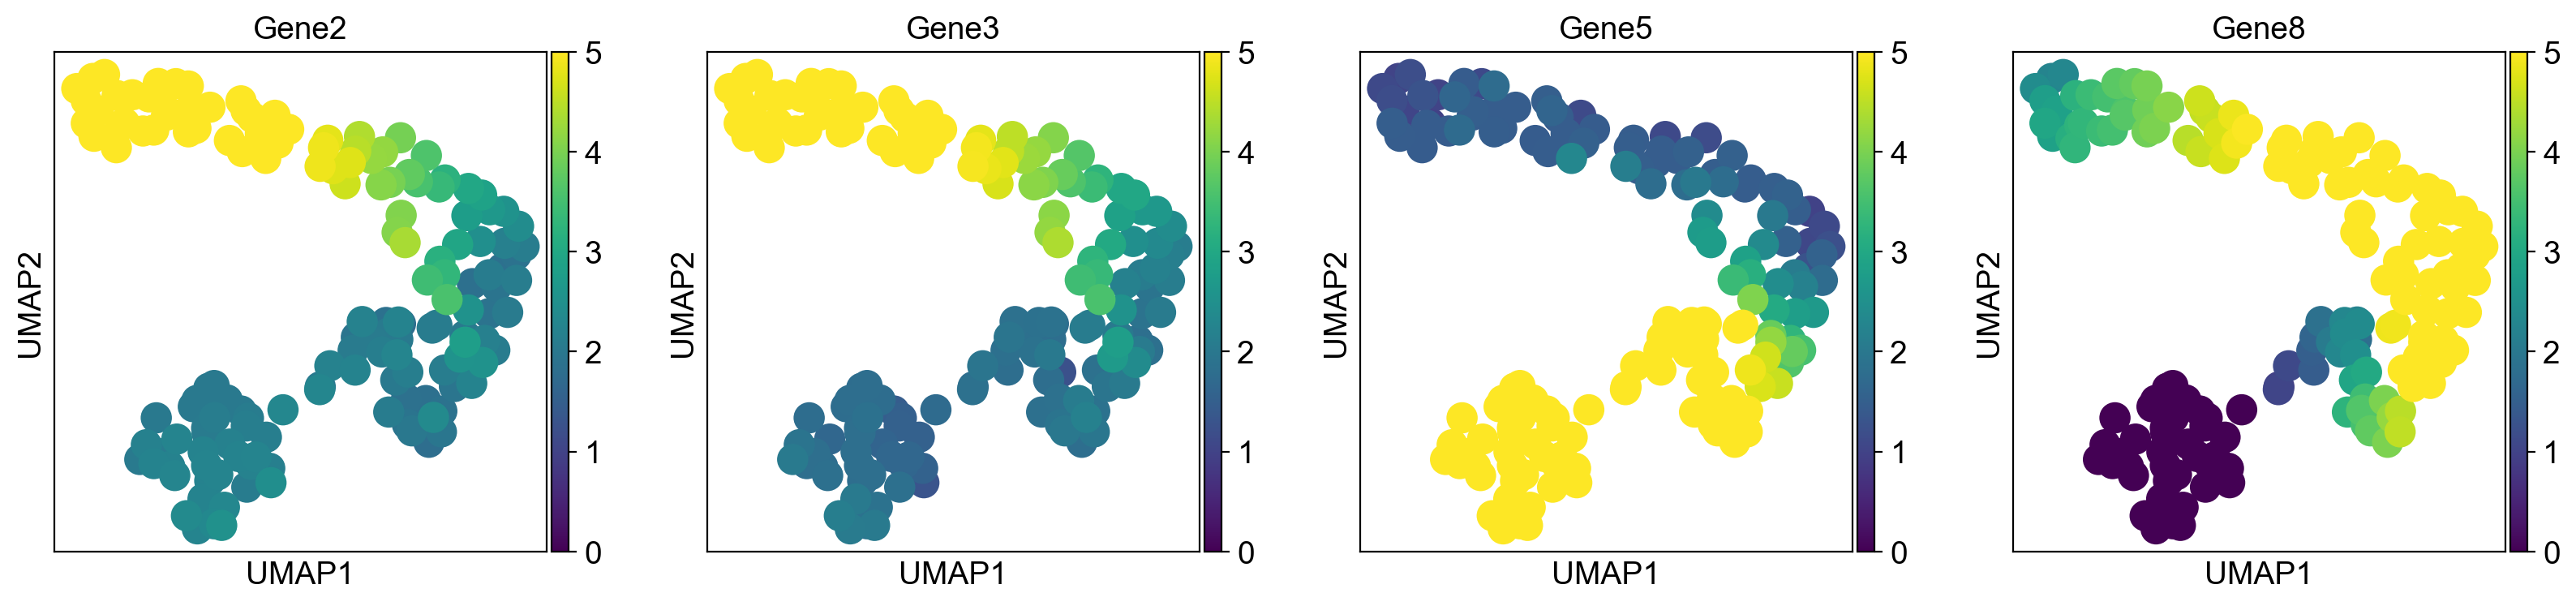

... storing 'Cell Type' as categorical


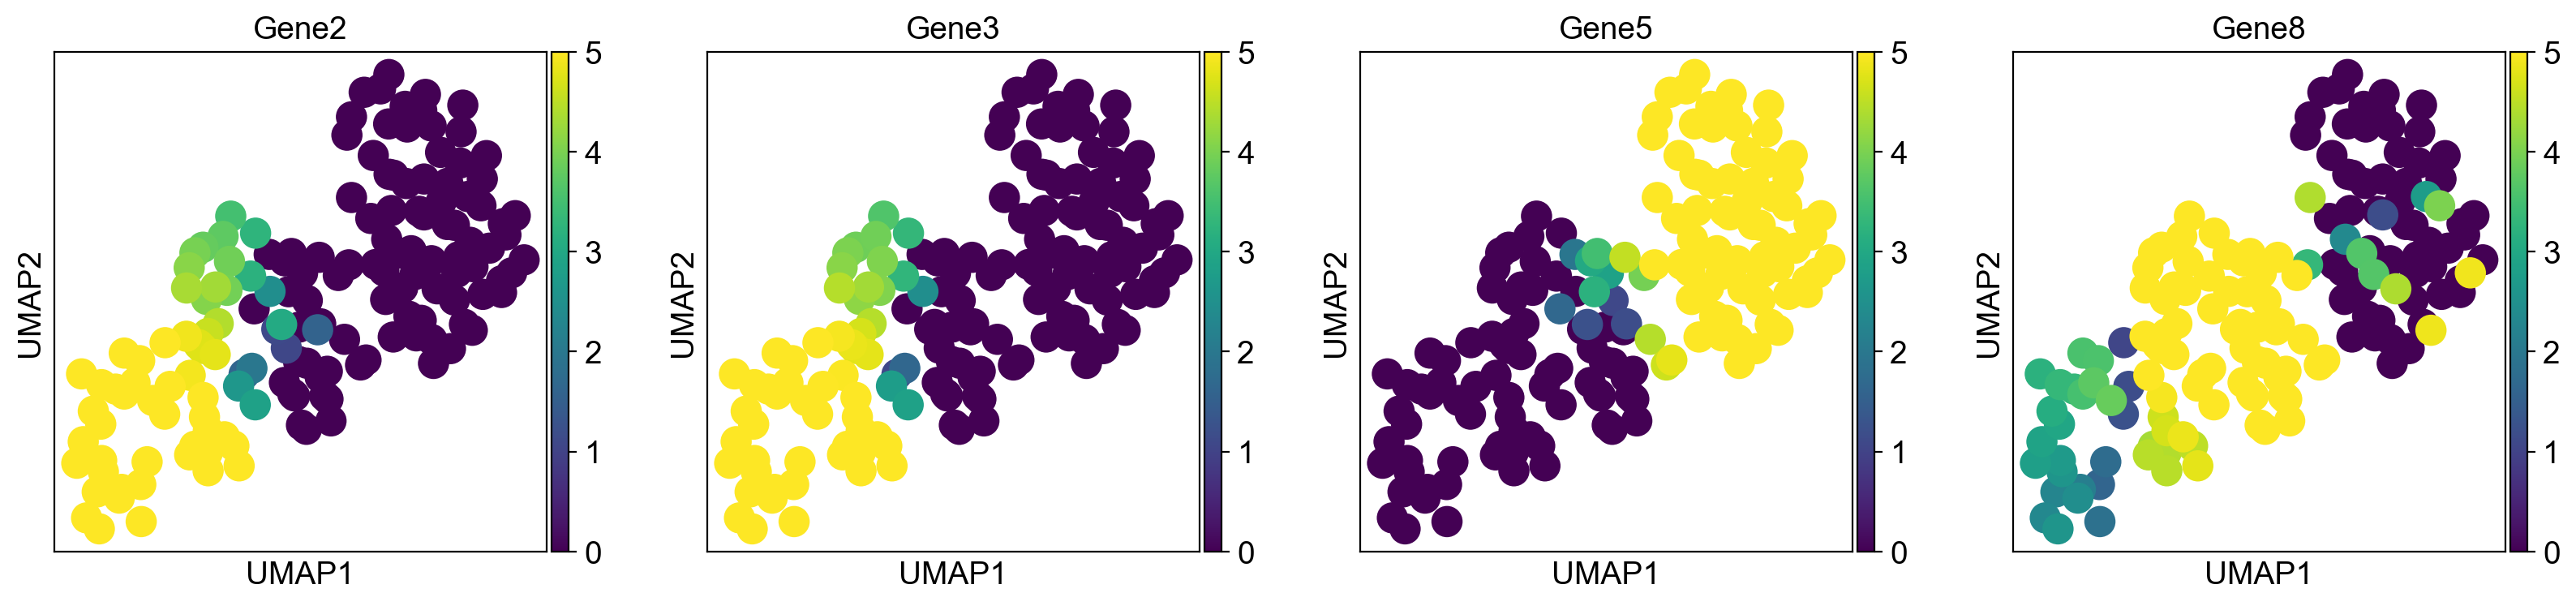

In [10]:
# filter for spots with tissue and perform standard normalization and dimension reduction
ad_rw_, ad_sb_ = ad_rw[mask].copy(), ad_sb[mask].copy()
for adata_ in [ad_rw_, ad_sb_]:
    # target sum is set to 1e3 here due to the small simulated library size
    # we recommend users follow standard protocols for their data (e.g. CPM or counts per 10K)
    sc.pp.normalize_total(adata_, target_sum=1e3); sc.pp.log1p(adata_)
    # we utilize all genes to construct a kNN graph due to the small dataset size
    # we recommend users follow standard pipelines for their data that likely is of larger size
    # e.g. constructing a kNN graph on the top principal components of their data
    sc.pp.neighbors(adata_, random_state=0, use_rep='X', n_neighbors=60)
    sc.tl.umap(adata_, random_state=0)
# plot the expression of randomly selected genes
sc.pl.umap(ad_rw_, color=genes, use_raw=False, vmin=0, vmax=5)
sc.pl.umap(ad_sb_, color=genes, use_raw=False, vmin=0, vmax=5)

Here, we show how dot plots can be utilized to analyze how well denoising has gone; users can use these plots to determine whether to repeat denoising with more optimal parameters (e.g. increased epochs or different ambient radius definitions). For this data, it can be seen how SpaceBender processing has significantly reduced off-target expression.

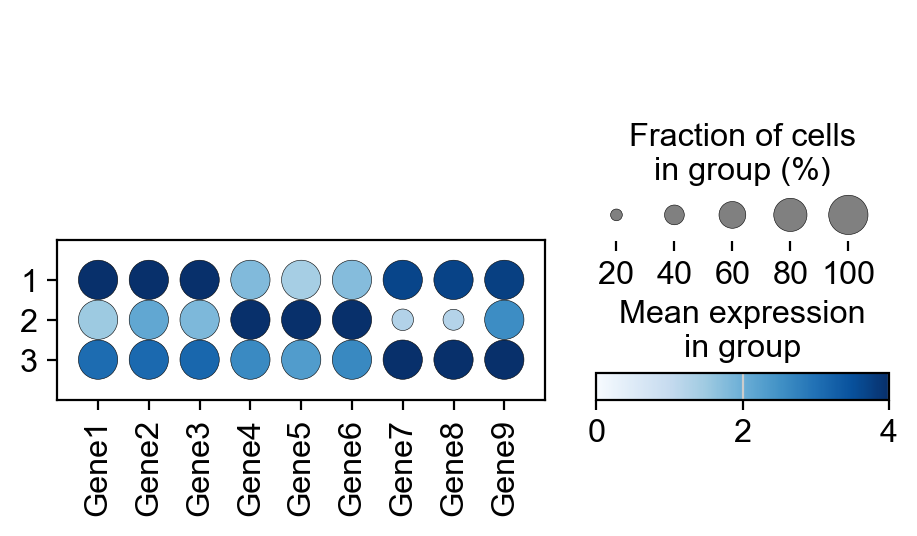

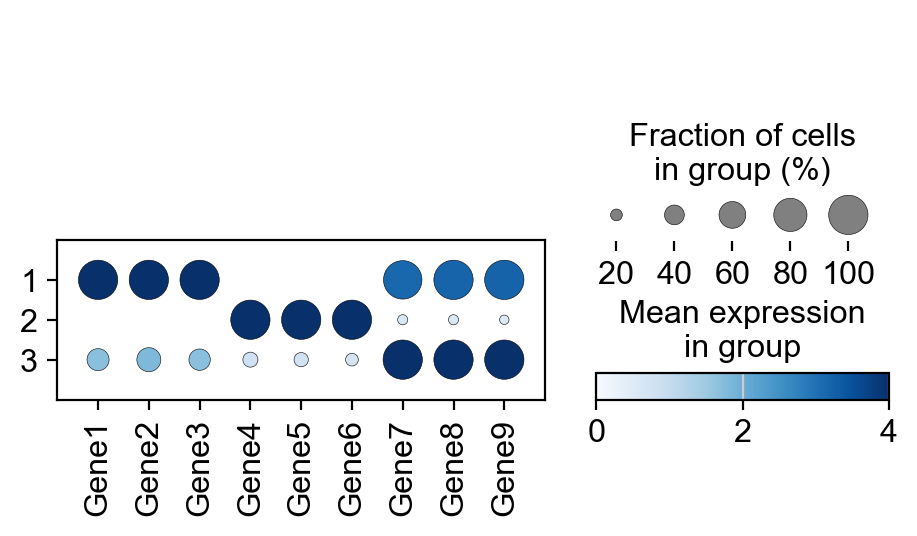

In [11]:
# comparing pre- and post-denoising results using dot plots
sc.pl.dotplot(ad_rw_, groupby='Cell Type', var_names=ad_sb_.var.index.tolist(),
              use_raw=False, vmin=0, vmax=4, cmap='Blues')
sc.pl.dotplot(ad_sb_, groupby='Cell Type', var_names=ad_sb_.var.index.tolist(),
              use_raw=False, vmin=0, vmax=4, cmap='Blues')

Here, we can observe how SpaceBender denoising preserves the original cell types and resolves them into three clusters.

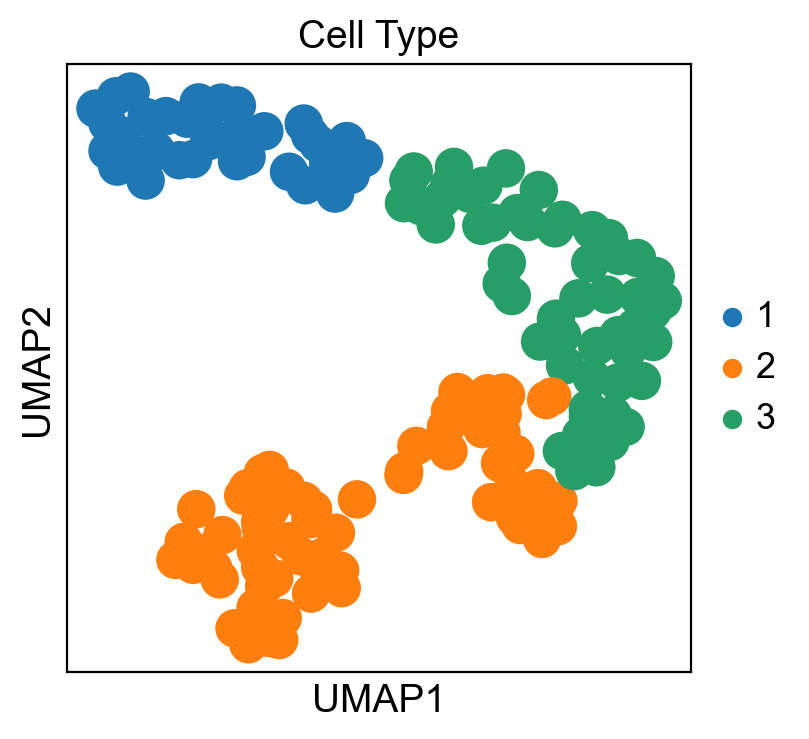

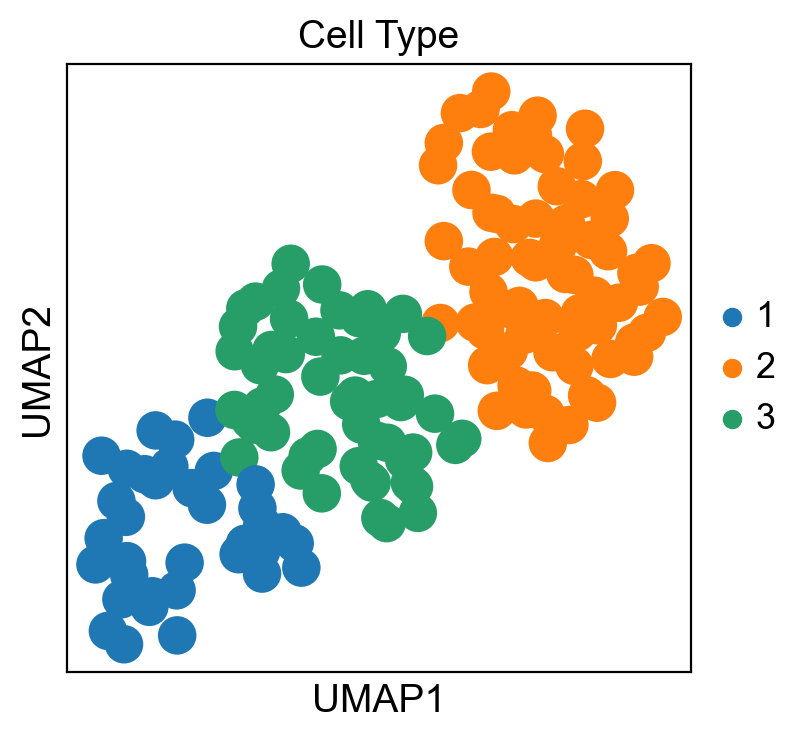

In [12]:
# visualization of observation-level annotations
sc.pl.umap(ad_rw_, color=['Cell Type'], use_raw=False)
sc.pl.umap(ad_sb_, color=['Cell Type'], use_raw=False)

We thank the user for their interest in our tool and we are always happy to address any questions on our GitHub or via email (dgchen@mednet.ucla.edu).